<a href="https://colab.research.google.com/github/Aurora-DS-1728821/AuroraDS-AnalyticsEngineering/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [9]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [10]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [11]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [12]:
trips.head()
stations = tables["stations"]
stations.head()
bikes = tables["bikes"]
bikes.head()

,bike_id,bike_type,purchase_year
0,B001,Standard,2021
1,B002,Electric,2022
2,B003,electric,2024
3,B004,Standard,2021
4,B005,STANDARD,2022


In [13]:
print("=== 1. STATIONS TABLE CHECK ===")
print("Missing values per column:\n", stations.isnull().sum())
print("\nDuplicate rows:", stations.duplicated().sum())
print("\nUnique zones:", stations['zone'].unique())
print("\nStation details:")
display(stations.describe(include='all'))

=== 1. STATIONS TABLE CHECK ===
Missing values per column:
 station_id      0
station_name    0
zone            0
capacity        1
dtype: int64

Duplicate rows: 0

Unique zones: ['Centre' 'North' 'West' 'South' 'East']

Station details:


,station_id,station_name,zone,capacity
count,12,12,12,11.000000
unique,12,12,5,NaN
top,S01,Market Square,Centre,NaN
freq,1,1,5,NaN
mean,NaN,NaN,NaN,22.909091
std,NaN,NaN,NaN,5.539938
min,NaN,NaN,NaN,14.000000
25%,NaN,NaN,NaN,19.000000
50%,NaN,NaN,NaN,24.000000
75%,NaN,NaN,NaN,27.500000


In [14]:
print("=== 2. BIKES TABLE CHECK ===")
print("Missing values per column:\n", bikes.isnull().sum())
print("\nDuplicate rows:", bikes.duplicated().sum())
print("\nUnique purchase years:", sorted(bikes['purchase_year'].unique()))
print("\nBike details:")
display(bikes.describe(include='all'))

=== 2. BIKES TABLE CHECK ===
Missing values per column:
 bike_id          0
bike_type        0
purchase_year    0
dtype: int64

Duplicate rows: 0

Unique purchase years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Bike details:


,bike_id,bike_type,purchase_year
count,60,60,60.000000
unique,60,7,NaN
top,B001,Standard,NaN
freq,1,36,NaN
mean,NaN,NaN,2022.550000
std,NaN,NaN,1.185005
min,NaN,NaN,2021.000000
25%,NaN,NaN,2021.000000
50%,NaN,NaN,2023.000000
75%,NaN,NaN,2024.000000


In [15]:
print("=== 3. TRIPS TABLE CHECK ===")
print("Missing values per column:\n", trips.isnull().sum())
print("\nDuplicate rows:", trips.duplicated().sum())
print("\nTrip duration summary:")
display(trips['duration_min'].describe())
print("\nChecking if duration has any negative or zero values:", (trips['duration_min'] <= 0).sum())

=== 3. TRIPS TABLE CHECK ===
Missing values per column:
 trip_id              0
bike_id              0
start_station_id     0
end_station_id       0
start_time           0
duration_min        30
user_type            0
dtype: int64

Duplicate rows: 12

Trip duration summary:


,duration_min
count,582.000000
mean,27.891753
std,145.064305
min,4.000000
25%,12.000000
50%,16.000000
75%,22.000000
max,2880.000000



Checking if duration has any negative or zero values: 0


In [ ]:
#Check the data distributions for all the trips duration
import matplotlib.pyplot as plt
import seaborn as sns




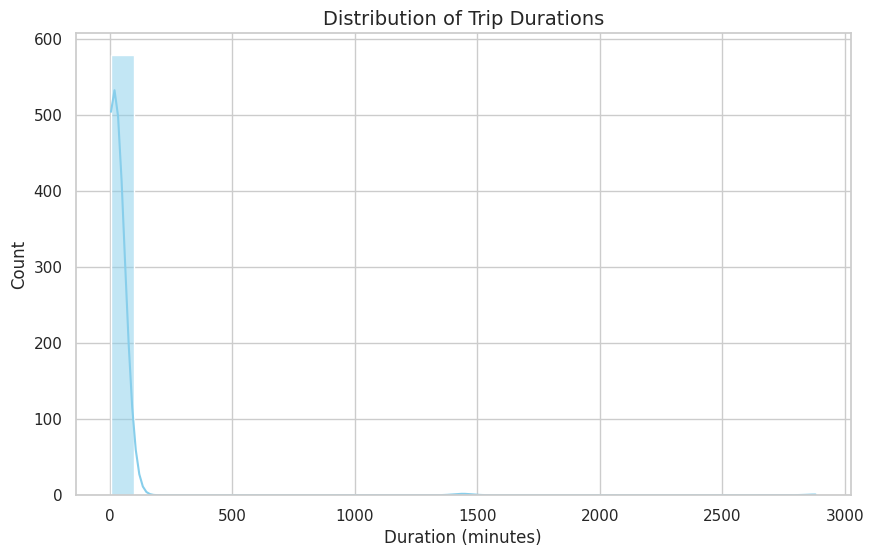

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# Plot the distribution of duration_min
plt.figure(figsize=(10, 6))
sns.histplot(data=trips, x='duration_min', kde=True, bins=30, color='skyblue')

plt.title('Distribution of Trip Durations', fontsize=14)
plt.xlabel('Duration (minutes)', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.show()

The data does not look properly formatted across for all the columns in the different tables. Identified issues:
* "Bikes" df:
    * bike_type - some values are all caps, some others are all in small case
* "Trips" df:
  * user_type - some values are all caps, some others are all in small case

There is also missing data from "duration_min" variable in "trips" and 12 duplicate rows. I will remove the duplicates and the NaN values.After cleaning up the values I will plot a distribution to spot any outliers.

  I will use bike_id to join "bikes" and "trips" and start_station_id = station_id to connect "trips" and "stations". From there I will group by bike_type and calculate the average duration for a trip based on the bike_type.

## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

In [18]:
# 1. Clean 'user_type' in trips: strip extra spaces and capitalize
trips['user_type'] = trips['user_type'].str.strip().str.capitalize()
print("Cleaned user types:", trips['user_type'].unique())


Cleaned user types: ['Casual' 'Member']


In [19]:
# 2. Clean 'bike_type' in bikes: strip extra spaces, capitalize, and standardize 'E-bike' to 'Electric'
bikes['bike_type'] = bikes['bike_type'].str.strip().str.capitalize()
bikes['bike_type'] = bikes['bike_type'].replace({'E-bike': 'Electric'})
print("Cleaned bike types:", bikes['bike_type'].unique())

Cleaned bike types: ['Standard' 'Electric']


In [20]:
# 3. Remove duplicate rows in trips
initial_count = len(trips)
trips.drop_duplicates(inplace=True)
final_count = len(trips)

print(f"Removed {initial_count - final_count} duplicate rows.")
print(f"New shape of trips: {trips.shape}")

Removed 12 duplicate rows.
New shape of trips: (600, 7)


In [21]:
# 4. Remove rows with missing duration_min values
initial_trips = len(trips)
trips = trips.dropna(subset=['duration_min'])
final_trips = len(trips)

print(f"Removed {initial_trips - final_trips} rows with missing durations.")
print(f"New shape of trips: {trips.shape}")

# Update the tables dictionary to keep everything synced
tables["trips"] = trips

Removed 30 rows with missing durations.
New shape of trips: (570, 7)


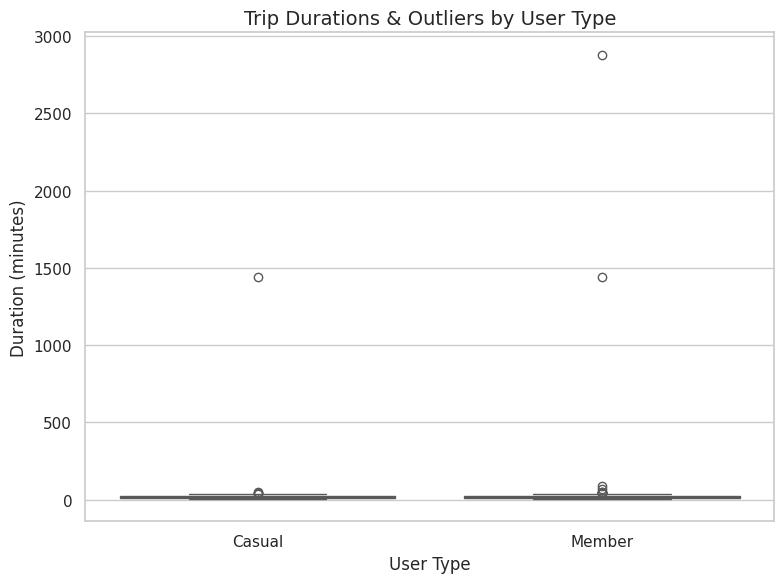

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a single plot focusing only on the outliers by user type
plt.figure(figsize=(8, 6))

sns.boxplot(data=trips, x='user_type', y='duration_min', palette='Set2', hue='user_type', legend=False)
plt.title('Trip Durations & Outliers by User Type', fontsize=14)
plt.xlabel('User Type', fontsize=12)
plt.ylabel('Duration (minutes)', fontsize=12)

plt.tight_layout()
plt.show()

In [25]:
# 1. Identify and display the extreme outliers (trips over 10 hours / 600 minutes)
outliers = trips[trips['duration_min'] > 600]
print("=== OUTLIER TRIPS IDENTIFIED ===")
display(outliers)

# 2. Filter them out from our main dataset
trips_cleaned = trips[trips['duration_min'] <= 600]

# 3. Update the global variables and tables dictionary to use the cleaned dataset
trips = trips_cleaned
tables["trips"] = trips

print(f"\nOriginal trips count: {len(trips_cleaned) + len(outliers)}")
print(f"Trips remaining after removing outliers: {len(trips)}")

=== OUTLIER TRIPS IDENTIFIED ===


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
80,T0081,B010,S12,S11,2025-03-04 21:57:00,2880.0,Member
143,T0143,B020,S09,S10,2025-03-08 12:23:00,1440.0,Casual
287,T0284,B046,S08,S03,2025-03-15 20:25:00,1440.0,Member



Original trips count: 570
Trips remaining after removing outliers: 567


## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

In [26]:
# Create a joined table between trips and stations, joined by start_station_id = station_id.
joined = trips.merge(stations, left_on="start_station_id", right_on="station_id", how="inner")
display(joined.head())



,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type,station_id,station_name,zone,capacity
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual,S05,Park Road,South,22.0
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,Casual,S12,Cathedral Close,Centre,28.0
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual,S11,Sports Centre,West,15.0
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member,S04,University Gate,West,28.0
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member,S01,Market Square,Centre,29.0


In [27]:
#Create the final "master" table by joining "bikes" too by bike_id

joined_final = joined.merge(bikes, left_on="bike_id", right_on="bike_id", how="inner")
display(joined_final[['bike_id', 'trip_id', 'start_station_id', 'duration_min', 'zone', 'bike_type']].head())

,bike_id,trip_id,start_station_id,duration_min,zone,bike_type
0,B028,T0001,S05,21.0,South,Standard
1,B043,T0002,S12,27.0,Centre,Standard
2,B045,T0003,S11,18.0,West,Standard
3,B051,T0004,S04,34.0,West,Electric
4,B049,T0005,S01,16.0,Centre,Standard


In [31]:
# Calculate the average trip duration by bike type and by the zone of the start station.
average_duration_by_zone = joined_final.groupby(['bike_type', 'zone'])['duration_min'].mean()

print(average_duration_by_zone)



bike_type  zone  
Electric   Centre    14.506173
           East      15.727273
           North     15.956522
           South     13.416667
           West      15.681818
Standard   Centre    18.925581
           East      19.500000
           North     20.358974
           South     19.474576
           West      19.821918
Name: duration_min, dtype: float64


## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

In [33]:
# Check the shape of the df (rows, columns)
print("DataFrame shape (rows, columns):", joined_final.shape)


#Check the shape of the trips df (make sure it's the same as the final joined df)
print("DataFrame shape (rows, columns):", trips.shape)

#Spot Check records
joined_final.sample(10)


DataFrame shape (rows, columns): (567, 13)
DataFrame shape (rows, columns): (567, 7)


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type,station_id,station_name,zone,capacity,bike_type,purchase_year
448,T0477,B007,S03,S01,2025-03-24 22:08:00,23.0,Casual,S03,Canal Basin,North,24.0,Standard,2024
432,T0459,B039,S11,S01,2025-03-24 09:45:00,15.0,Casual,S11,Sports Centre,West,15.0,Standard,2024
464,T0493,B004,S02,S01,2025-03-25 23:21:00,11.0,Member,S02,Railway Station,Centre,23.0,Standard,2021
96,T0105,B047,S02,S02,2025-03-06 16:20:00,11.0,Member,S02,Railway Station,Centre,23.0,Standard,2021
261,T0277,B016,S05,S01,2025-03-15 17:36:00,19.0,Member,S05,Park Road,South,22.0,Standard,2023
505,T0535,B021,S08,S12,2025-03-28 09:13:00,21.0,Member,S08,Riverside Walk,South,14.0,Standard,2022
334,T0355,B053,S09,S04,2025-03-19 11:13:00,8.0,Casual,S09,Old Town Hall,Centre,NaN,Electric,2023
337,T0359,B048,S02,S11,2025-03-19 18:12:00,22.0,Member,S02,Railway Station,Centre,23.0,Standard,2021
114,T0125,B017,S08,S03,2025-03-07 08:47:00,17.0,Casual,S08,Riverside Walk,South,14.0,Standard,2023
54,T0058,B011,S08,S09,2025-03-04 07:04:00,12.0,Member,S08,Riverside Walk,South,14.0,Electric,2021


I expected joined_final to have the same amount of rows as trips as we wanted to check the average trip duration for all trips where the record was not a duplicate and where the duration_min was not NaN

In [42]:
# Check the average duration and number of trips by bike type and zone using SQL
query_result = q("""
    SELECT
        bike_type,
        zone,
        COUNT(*) AS total_trips,
        ROUND(AVG(duration_min), 2) AS avg_duration_minutes
    FROM joined_final
    GROUP BY bike_type, zone
    ORDER BY bike_type,zone
""")

display(query_result)

,bike_type,zone,total_trips,avg_duration_minutes
0,Electric,Centre,81,14.51
1,Electric,East,11,15.73
2,Electric,North,23,15.96
3,Electric,South,24,13.42
4,Electric,West,22,15.68
5,Standard,Centre,215,18.93
6,Standard,East,20,19.50
7,Standard,North,39,20.36
8,Standard,South,59,19.47
9,Standard,West,73,19.82


## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*



How do I change the column in a dataframe so that all the characters are consistent (all small case)

or rather, the majority of the values are starting with a capital and then continuing in lower case, but some are all caps. I want that to be all the same format (first cap and then lower case)


ok there is another problem. There are some extra spaces too i.e. Electric is the same as "Electric " how do I fix it?

## 6. What I could not verify

*What remains unchecked? What would you do next?*

Could not verify the outliers, why did we have such high durations? Were they mistakes in the data or correct entries?

Data integrity - what is the data source? is it reliable? There is not data dictionary.